(1692, 6)
<class 'pandas.DataFrame'>
DatetimeIndex: 1692 entries, 2010-06-29 to 2017-03-17
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       1692 non-null   float64
 1   High       1692 non-null   float64
 2   Low        1692 non-null   float64
 3   Close      1692 non-null   float64
 4   Volume     1692 non-null   int64  
 5   Adj Close  1692 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 92.5 KB
[ 16.139999  16.4       17.389999 ... 282.98999  284.01001  287.670013] this is the sorted data of open share price
train size: 1269 test size: 423


C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        29,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,465 (165.88 KB)

 Trainable params: 42,465 (165.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 15s 139ms/step - loss: 0.0214 - mean_squared_error: 0.0214
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.0014 - mean_squared_error: 0.0014
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0011 - mean_squared_error: 0.0011
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0011 - mean_squared_error: 0.0011
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 0.0011 - mean_squared_error: 0.0011
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0010 - mean_squared_error: 0.0010
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 9.6062e-04 - mean_squared_error: 9.6062e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 9.0712e-04 - mean_squared_error: 9.0712e-04
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 8.6999e-04 - mean_squared_error: 8.6999e-04
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 8.4795e-04 - mean_squared_error: 8.4795e-04
Epoch

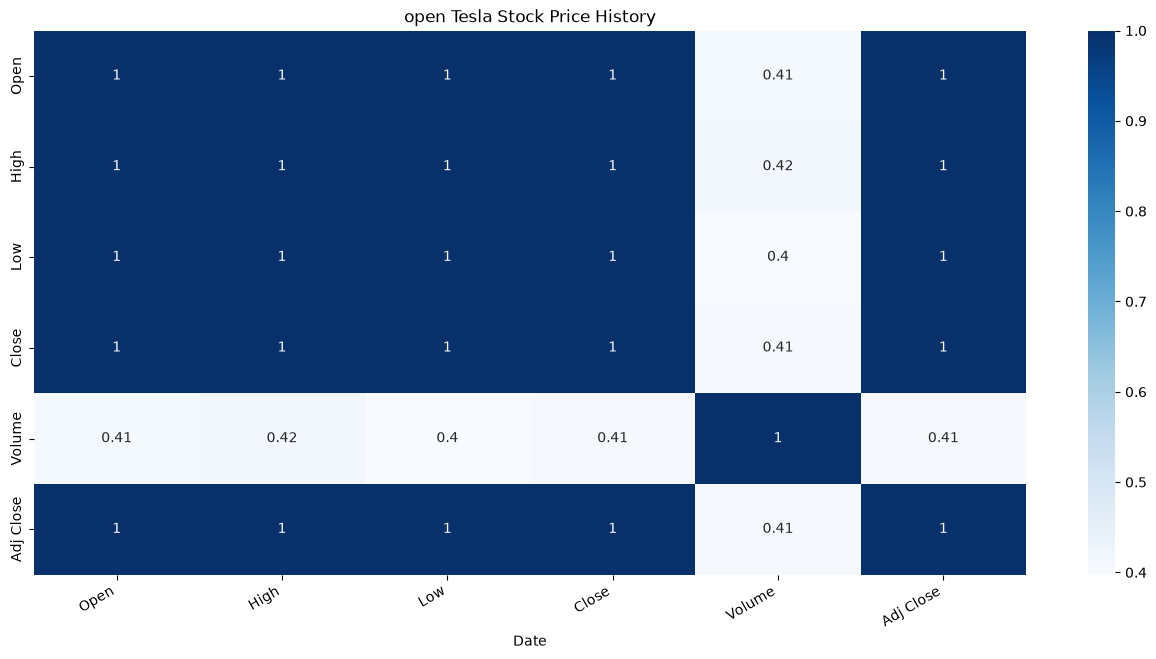

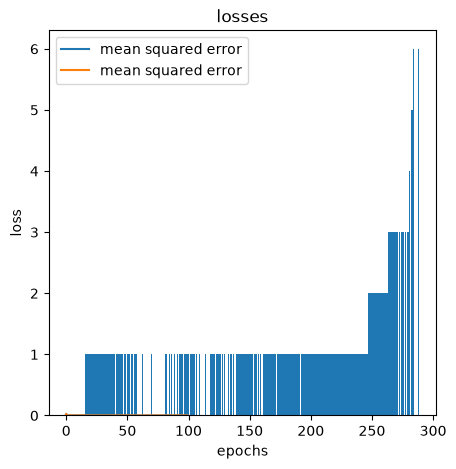

14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step
6.34


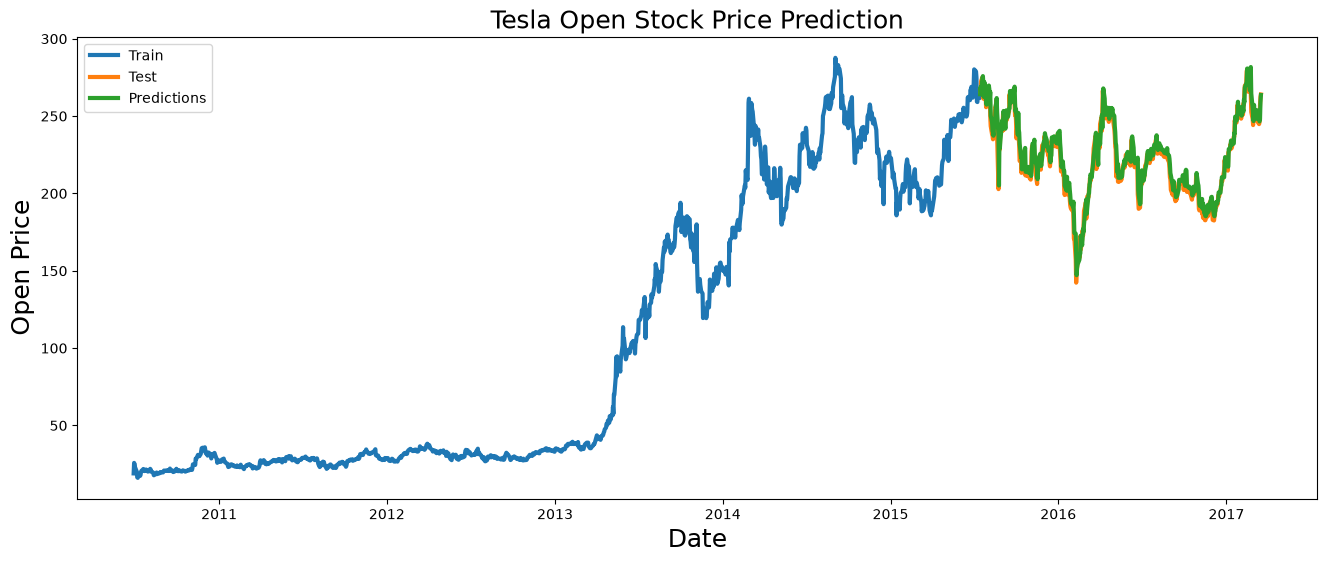

In [1]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

df=pd.read_csv(r"C:\Users\HP\Documents\Tesla.csv", parse_dates=True , index_col="Date")
df.head()
df.describe()
print(df.shape)
df.info()

plt.figure(figsize=(15,7))
sns.heatmap(df.corr(),cbar=True,annot=True,cmap='Blues')

df["Open"].plot(figsize=(16,8),color='red')
plt.title("open Tesla Stock Price History")

print(np.sort(df['Open']),"this is the sorted data of open share price")
plt.figure(figsize=(5,5))
plt.bar(list(np.sort(df['Open'].value_counts().keys())),list(np.sort(df['Open'].value_counts())))
plt.title("sorted open share price graph")
plt.xlabel("price of open share")
plt.ylabel("frequency")

df.isna().any()

dataset=df["Open"]
dataset=pd.DataFrame(dataset)
data=dataset.values
data.shape

scaler=MinMaxScaler(feature_range=(0,1))
scaled_data=scaler.fit_transform(data)

train_size=int(len(data)*.75)
test_size=len(data)-train_size

print("train size:",train_size,"test size:",test_size)

train_data=scaled_data[:train_size,0:1]
test_data=scaled_data[train_size-60:,0:1]


train_data.shape,test_data.shape

x_train=[]
y_train=[]

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i,0])
    y_train.append(train_data[i,0])

x_train,y_train=np.array(x_train),np.array(y_train)

x_train=np.reshape(x_train,(x_train.shape[0],x_train.shape[1],1))

x_train.shape,y_train.shape

model=Sequential()
model.add(LSTM(50,return_sequences=True,input_shape=(x_train.shape[1],1)))
model.add(LSTM(64, return_sequences=False))
model.add(Dense(32))
model.add(Dense(16))
model.add(Dense(1))
model.compile(optimizer='adam',loss='mse',metrics=["mean_squared_error"])

model.summary()

callbacks=[EarlyStopping(monitor='loss',patience=10,restore_best_weights=True)]
history=model.fit(x_train,y_train,epochs=100,batch_size=32,callbacks=callbacks)

plt.plot(history.history["loss"])
plt.plot(history.history["mean_squared_error"])
plt.legend(['mean squared error','mean squared error'])
plt.title("losses")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.show()

x_test=[]
y_test=[]

for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i,0])
    y_test.append(test_data[i,0])
x_test,y_test=np.array(x_test),np.array(y_test)
x_test=np.reshape(x_test,(x_test.shape[0],x_test.shape[1],1))

x_test.shape , y_test.shape

predictions =model.predict(x_test)
predictions =scaler.inverse_transform(predictions)
predictions.shape

y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))
RMSE = float(np.sqrt(np.mean((y_test_inv - predictions)**2)).round(2))
print(RMSE)

train = dataset.iloc[:train_size, 0:1]
test = dataset.iloc[train_size:, 0:1]
test['Predictions'] = predictions

plt.figure(figsize=(16,6))
plt.title('Tesla Open Stock Price Prediction', fontsize=18)
plt.xlabel('Date', fontsize=18)
plt.ylabel('Open Price', fontsize=18)
plt.plot(train['Open'], linewidth=3)
plt.plot(test['Open'], linewidth=3)
plt.plot(test["Predictions"], linewidth=3)
plt.legend(['Train', 'Test', 'Predictions'])

model.save("tesla_stock_model.h5")

from tensorflow.keras.models import load_model

In [2]:
load_model("tesla_stock_model.h5")

<Sequential name=sequential, built=True>